In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.edgecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
})

matches = pd.read_csv("matches.csv")

matches["date"] = pd.to_datetime(
    matches["date"],
    format="%d/%m/%Y",
    errors="coerce"
)

print("Number of matches:", len(matches))
print("Missing dates:", matches["date"].isna().sum())
print("Duplicate match records:", matches.duplicated(
    subset=["date", "home_team", "away_team"]
).sum())

print(matches[[
    "date", "home_team", "away_team",
    "home_score", "away_score"
]].head())

Number of matches: 104
Missing dates: 0
Duplicate match records: 0
        date       home_team     away_team  home_score  away_score
0 2026-06-11          Mexico  South Africa           2           0
1 2026-06-11  Korea Republic       Czechia           2           1
2 2026-06-12          Canada   Bosnia–Herz           1           1
3 2026-06-12   United States      Paraguay           4           1
4 2026-06-13           Qatar   Switzerland           1           1


In [4]:
import pandas as pd
import numpy as np

matches = pd.read_csv("matches.csv")
results = pd.read_csv("results.csv")
rankings = pd.read_csv("ranking_fifa_historical.csv")
elo = pd.read_csv("elo_ratings_wc2026.csv")

# Standardise dates
matches["date"] = pd.to_datetime(
    matches["date"], dayfirst=True, errors="coerce"
)

results["date"] = pd.to_datetime(
    results["date"], errors="coerce"
)

rankings["date"] = pd.to_datetime(
    rankings["date"], errors="coerce"
)

elo["snapshot_date"] = pd.to_datetime(
    elo["snapshot_date"], errors="coerce"
)

print("World Cup matches:", matches.shape)
print("Historical results:", results.shape)
print("FIFA rankings:", rankings.shape)
print("Elo ratings:", elo.shape)

World Cup matches: (104, 42)
Historical results: (49945, 9)
FIFA rankings: (67894, 6)
Elo ratings: (4683, 23)


In [5]:
wc_teams = set(matches["home_team"]) | set(matches["away_team"])
historical_teams = set(results["home_team"]) | set(results["away_team"])
ranking_teams = set(rankings["team"])
elo_teams = set(elo["country"])

print("World Cup teams:", len(wc_teams))

print("\nTeams missing from historical results:")
print(sorted(wc_teams - historical_teams))

print("\nTeams missing from FIFA rankings:")
print(sorted(wc_teams - ranking_teams))

print("\nTeams missing from Elo ratings:")
print(sorted(wc_teams - elo_teams))

World Cup teams: 48

Teams missing from historical results:
['Bosnia–Herz', 'Cabo Verde', 'Congo DR', 'Czechia', "Côte d'Ivoire", 'IR Iran', 'Korea Republic', 'Türkiye']

Teams missing from FIFA rankings:
['Bosnia–Herz', 'United States']

Teams missing from Elo ratings:
['Bosnia–Herz', 'Cabo Verde', 'Congo DR', "Côte d'Ivoire", 'IR Iran', 'Korea Republic', 'Türkiye']


In [6]:
# Check the World Cup team names exactly as stored
print("MATCHES:")
print(sorted(wc_teams))

print("\nHISTORICAL RESULTS — possible matching names:")
for name in ["Bosnia", "Cabo", "Cape Verde", "Congo", "Czech", "Ivory",
             "Iran", "Korea", "Turkey", "Türkiye", "United States"]:
    found = results[
        results["home_team"].str.contains(name, case=False, na=False) |
        results["away_team"].str.contains(name, case=False, na=False)
    ]
    teams = set(found["home_team"]) | set(found["away_team"])
    if teams:
        print(name, "->", sorted(teams))

print("\nFIFA RANKINGS — possible matching names:")
for name in ["Bosnia", "United States", "USA", "Türkiye", "Turkey"]:
    found = rankings[
        rankings["team"].str.contains(name, case=False, na=False)
    ]
    if not found.empty:
        print(name, "->", sorted(found["team"].unique()))

print("\nELO — possible matching names:")
for name in ["Bosnia", "Cabo", "Cape Verde", "Congo", "Ivory",
             "Iran", "Korea", "Turkey", "Türkiye"]:
    found = elo[elo["country"].str.contains(name, case=False, na=False)]
    if not found.empty:
        print(name, "->", sorted(found["country"].unique()))

MATCHES:
['Algeria', 'Argentina', 'Australia', 'Austria', 'Belgium', 'Bosnia–Herz', 'Brazil', 'Cabo Verde', 'Canada', 'Colombia', 'Congo DR', 'Croatia', 'Curaçao', 'Czechia', "Côte d'Ivoire", 'Ecuador', 'Egypt', 'England', 'France', 'Germany', 'Ghana', 'Haiti', 'IR Iran', 'Iraq', 'Japan', 'Jordan', 'Korea Republic', 'Mexico', 'Morocco', 'Netherlands', 'New Zealand', 'Norway', 'Panama', 'Paraguay', 'Portugal', 'Qatar', 'Saudi Arabia', 'Scotland', 'Senegal', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'Tunisia', 'Türkiye', 'United States', 'Uruguay', 'Uzbekistan']

HISTORICAL RESULTS — possible matching names:
Bosnia -> ['Albania', 'Algeria', 'Andorra', 'Argentina', 'Armenia', 'Austria', 'Azerbaijan', 'Bahrain', 'Bangladesh', 'Belarus', 'Belgium', 'Bosnia and Herzegovina', 'Brazil', 'Bulgaria', 'Canada', 'Chile', 'China', 'Costa Rica', 'Croatia', 'Cyprus', 'Czech Republic', 'Denmark', 'Egypt', 'England', 'Estonia', 'Faroe Islands', 'Finland', 'France', 'Georgia', 'Germany', 'Ghana'

In [7]:
# Historical international results
results_names = {
    "Bosnia and Herzegovina": "Bosnia–Herz",
    "Cape Verde": "Cabo Verde",
    "DR Congo": "Congo DR",
    "Czech Republic": "Czechia",
    "Ivory Coast": "Côte d'Ivoire",
    "Iran": "IR Iran",
    "South Korea": "Korea Republic",
    "Turkey": "Türkiye",
}

for col in ["home_team", "away_team"]:
    results[col] = results[col].replace(results_names)

# FIFA rankings
ranking_names = {
    "Bosnia and Herzegovina": "Bosnia–Herz",
    "USA": "United States",
    "Turkey": "Türkiye",
}

rankings["team"] = rankings["team"].replace(ranking_names)

# Elo ratings
elo_names = {
    "Bosnia and Herzegovina": "Bosnia–Herz",
    "Cape Verde": "Cabo Verde",
    "DR Congo": "Congo DR",
    "Ivory Coast": "Côte d'Ivoire",
    "Iran": "IR Iran",
    "South Korea": "Korea Republic",
    "Turkey": "Türkiye",
}

elo["country"] = elo["country"].replace(elo_names)

# Recheck coverage
ranking_teams = set(rankings["team"])
elo_teams = set(elo["country"])
historical_teams = set(results["home_team"]) | set(results["away_team"])

print("Missing from historical results:", sorted(wc_teams - historical_teams))
print("Missing from FIFA rankings:", sorted(wc_teams - ranking_teams))
print("Missing from Elo:", sorted(wc_teams - elo_teams))

Missing from historical results: []
Missing from FIFA rankings: []
Missing from Elo: []


In [8]:
# Keep only the columns needed for historical form
results = results[
    ["date", "home_team", "away_team", "home_score", "away_score"]
].copy()

# Ensure dates and scores are valid
results["date"] = pd.to_datetime(results["date"], errors="coerce")

results["home_score"] = pd.to_numeric(
    results["home_score"], errors="coerce"
)
results["away_score"] = pd.to_numeric(
    results["away_score"], errors="coerce"
)

results = results.dropna(
    subset=["date", "home_team", "away_team", "home_score", "away_score"]
)

results = results.sort_values("date").reset_index(drop=True)

print("Clean historical results:", results.shape)
print("Date range:", results["date"].min(), "to", results["date"].max())
print(results.head())

Clean historical results: (49945, 5)
Date range: 1872-11-30 00:00:00 to 2026-10-06 00:00:00
        date home_team away_team  home_score  away_score
0 1872-11-30  Scotland   England           0           0
1 1873-03-08   England  Scotland           4           2
2 1874-03-07  Scotland   England           2           1
3 1875-03-06   England  Scotland           2           2
4 1876-03-04  Scotland   England           3           0


In [9]:
matches = matches.sort_values("date").reset_index(drop=True)

print("World Cup date range:", matches["date"].min(), "to", matches["date"].max())
print(matches[["date", "home_team", "away_team", "home_score", "away_score"]].head())

World Cup date range: 2026-06-11 00:00:00 to 2026-07-19 00:00:00
        date       home_team     away_team  home_score  away_score
0 2026-06-11          Mexico  South Africa           2           0
1 2026-06-11  Korea Republic       Czechia           2           1
2 2026-06-12          Canada   Bosnia–Herz           1           1
3 2026-06-12   United States      Paraguay           4           1
4 2026-06-13           Qatar   Switzerland           1           1


In [10]:
def get_recent_form(team, match_date, results, n=5):
    # Only matches before the World Cup match date
    past = results[
        (results["date"] < match_date) &
        (
            (results["home_team"] == team) |
            (results["away_team"] == team)
        )
    ].sort_values("date", ascending=False).head(n)

    # Require five previous matches for consistent comparisons
    if len(past) < n:
        return np.nan, np.nan

    wins = 0
    goals_scored = []

    for _, row in past.iterrows():
        if row["home_team"] == team:
            goals_for = row["home_score"]
            goals_against = row["away_score"]
        else:
            goals_for = row["away_score"]
            goals_against = row["home_score"]

        goals_scored.append(goals_for)

        if goals_for > goals_against:
            wins += 1

    win_percentage = wins / n
    average_goals = np.mean(goals_scored)

    return win_percentage, average_goals


# Calculate form for both teams
home_form = matches.apply(
    lambda row: get_recent_form(row["home_team"], row["date"], results),
    axis=1
)

away_form = matches.apply(
    lambda row: get_recent_form(row["away_team"], row["date"], results),
    axis=1
)

matches["home_win_pct_5"] = [x[0] for x in home_form]
matches["away_win_pct_5"] = [x[0] for x in away_form]
matches["home_avg_goals_5"] = [x[1] for x in home_form]
matches["away_avg_goals_5"] = [x[1] for x in away_form]

print(matches[[
    "date", "home_team", "away_team",
    "home_win_pct_5", "away_win_pct_5",
    "home_avg_goals_5", "away_avg_goals_5"
]].head(10))

print("\nMissing values:")
print(matches[[
    "home_win_pct_5", "away_win_pct_5",
    "home_avg_goals_5", "away_avg_goals_5"
]].isna().sum())

        date       home_team     away_team  home_win_pct_5  away_win_pct_5  \
0 2026-06-11          Mexico  South Africa             0.6             0.2   
1 2026-06-11  Korea Republic       Czechia             0.6             0.6   
2 2026-06-12          Canada   Bosnia–Herz             0.4             0.0   
3 2026-06-12   United States      Paraguay             0.4             0.6   
4 2026-06-13           Qatar   Switzerland             0.0             0.2   
5 2026-06-13          Brazil       Morocco             0.6             0.6   
6 2026-06-13       Australia       Türkiye             0.4             0.8   
7 2026-06-13           Haiti      Scotland             0.4             0.6   
8 2026-06-14         Germany       Curaçao             1.0             0.2   
9 2026-06-14     Netherlands         Japan             0.6             1.0   

   home_avg_goals_5  away_avg_goals_5  
0               1.8               0.8  
1               1.4               3.4  
2               1.4  

In [11]:
print("Latest FIFA ranking date:", rankings["date"].max())
print("Latest Elo snapshot date:", elo["snapshot_date"].max())

print("\nLatest FIFA ranking dates:")
print(sorted(rankings["date"].dropna().unique())[-5:])

print("\nLatest Elo snapshot dates:")
print(sorted(elo["snapshot_date"].dropna().unique())[-10:])

Latest FIFA ranking date: 2024-09-19 00:00:00
Latest Elo snapshot date: 2026-12-31 00:00:00

Latest FIFA ranking dates:
[Timestamp('2024-02-15 00:00:00'), Timestamp('2024-04-04 00:00:00'), Timestamp('2024-06-20 00:00:00'), Timestamp('2024-07-18 00:00:00'), Timestamp('2024-09-19 00:00:00')]

Latest Elo snapshot dates:
[Timestamp('2018-12-31 00:00:00'), Timestamp('2019-12-31 00:00:00'), Timestamp('2020-12-31 00:00:00'), Timestamp('2021-12-31 00:00:00'), Timestamp('2022-12-31 00:00:00'), Timestamp('2023-12-31 00:00:00'), Timestamp('2024-12-31 00:00:00'), Timestamp('2025-12-31 00:00:00'), Timestamp('2026-05-27 00:00:00'), Timestamp('2026-12-31 00:00:00')]


In [12]:
# Latest Elo snapshot strictly before the first World Cup match
first_match_date = matches["date"].min()

eligible_elo_dates = elo.loc[
    elo["snapshot_date"] < first_match_date, "snapshot_date"
]

latest_elo_date = eligible_elo_dates.max()
elo_pre_wc = elo[elo["snapshot_date"] == latest_elo_date].copy()

# Latest available FIFA ranking snapshot
latest_ranking_date = rankings["date"].max()
ranking_pre_wc = rankings[
    rankings["date"] == latest_ranking_date
].copy()

print("Elo snapshot selected:", latest_elo_date)
print("Teams in selected Elo snapshot:", elo_pre_wc["country"].nunique())
print("World Cup teams missing from Elo snapshot:",
      sorted(wc_teams - set(elo_pre_wc["country"])))

print("\nFIFA ranking snapshot selected:", latest_ranking_date)
print("Teams in selected FIFA snapshot:", ranking_pre_wc["team"].nunique())
print("World Cup teams missing from FIFA snapshot:",
      sorted(wc_teams - set(ranking_pre_wc["team"])))

print("\nSample Elo ratings:")
print(
    elo_pre_wc[elo_pre_wc["country"].isin(wc_teams)]
    [["country", "rating", "rank"]]
    .sort_values("rating", ascending=False)
    .head(10)
)

print("\nSample FIFA ranking records:")
print(
    ranking_pre_wc[ranking_pre_wc["team"].isin(wc_teams)]
    [["team", "total_points"]]
    .sort_values("total_points", ascending=False)
    .head(10)
)

Elo snapshot selected: 2026-05-27 00:00:00
Teams in selected Elo snapshot: 48
World Cup teams missing from Elo snapshot: []

FIFA ranking snapshot selected: 2024-09-19 00:00:00
Teams in selected FIFA snapshot: 211
World Cup teams missing from FIFA snapshot: ['New Zealand']

Sample Elo ratings:
          country  rating  rank
4635        Spain    2165     1
4636    Argentina    2113     2
4637       France    2081     3
4638      England    2020     4
4639       Brazil    1984     5
4640     Portugal    1984     5
4641     Colombia    1975     7
4642  Netherlands    1961     8
4643      Ecuador    1933     9
4644      Croatia    1930    10

Sample FIFA ranking records:
              team  total_points
67683    Argentina       1889.02
67684       France       1851.92
67685        Spain       1836.42
67686      England       1817.28
67687       Brazil       1772.02
67688      Belgium       1768.14
67689  Netherlands       1759.95
67690     Portugal       1752.14
67691     Colombia       1

In [13]:
print(
    rankings[rankings["team"].str.contains("New Zealand", case=False, na=False)]
    [["team", "date", "total_points"]]
    .sort_values("date")
    .tail(10)
)

                       team       date  total_points
1153   Aotearoa New Zealand 2023-07-20       1199.04
947    Aotearoa New Zealand 2023-09-21       1199.04
735    Aotearoa New Zealand 2023-10-26       1198.41
525    Aotearoa New Zealand 2023-11-30       1197.47
314    Aotearoa New Zealand 2023-12-21       1197.47
102    Aotearoa New Zealand 2024-02-15       1197.47
67153  Aotearoa New Zealand 2024-04-04       1197.68
67578  Aotearoa New Zealand 2024-06-20       1197.68
67354  Aotearoa New Zealand 2024-07-18       1245.73
67777  Aotearoa New Zealand 2024-09-19       1247.08


In [14]:
# Use the latest available FIFA snapshot
ranking_pre_wc = rankings[
    rankings["date"] == rankings["date"].max()
].copy()

ranking_pre_wc["fifa_rank"] = (
    ranking_pre_wc["total_points"]
    .rank(method="min", ascending=False)
)

# Elo snapshot before the tournament
elo_pre_wc = elo[
    elo["snapshot_date"] == pd.Timestamp("2026-05-27")
].copy()

# Lookups
fifa_rank_map = dict(zip(ranking_pre_wc["team"], ranking_pre_wc["fifa_rank"]))
elo_rating_map = dict(zip(elo_pre_wc["country"], elo_pre_wc["rating"]))

# Add features to each match
matches["home_fifa_rank"] = matches["home_team"].map(fifa_rank_map)
matches["away_fifa_rank"] = matches["away_team"].map(fifa_rank_map)

matches["home_elo"] = matches["home_team"].map(elo_rating_map)
matches["away_elo"] = matches["away_team"].map(elo_rating_map)

print(matches[[
    "home_team", "away_team",
    "home_fifa_rank", "away_fifa_rank",
    "home_elo", "away_elo"
]].head(10))

print("\nMissing values:")
print(matches[[
    "home_fifa_rank", "away_fifa_rank",
    "home_elo", "away_elo"
]].isna().sum())

        home_team     away_team  home_fifa_rank  away_fifa_rank  home_elo  \
0          Mexico  South Africa            17.0            59.0      1860   
1  Korea Republic       Czechia            23.0            46.0      1752   
2          Canada   Bosnia–Herz            38.0            75.0      1784   
3   United States      Paraguay            18.0            57.0      1721   
4           Qatar   Switzerland            44.0            15.0      1425   
5          Brazil       Morocco             5.0            14.0      1984   
6       Australia       Türkiye            25.0            26.0      1783   
7           Haiti      Scotland            86.0            52.0      1532   
8         Germany       Curaçao            13.0            88.0      1923   
9     Netherlands         Japan             7.0            16.0      1961   

   away_elo  
0      1524  
1      1726  
2      1594  
3      1833  
4      1889  
5      1822  
6      1902  
7      1767  
8      1436  
9      1904 

In [15]:
# Standardise the New Zealand name in the FIFA ranking dataset
rankings["team"] = rankings["team"].replace({
    "Aotearoa New Zealand": "New Zealand"
})

# Rebuild ranking snapshot and rank teams by points
ranking_pre_wc = rankings[
    rankings["date"] == rankings["date"].max()
].copy()

ranking_pre_wc["fifa_rank"] = (
    ranking_pre_wc["total_points"]
    .rank(method="min", ascending=False)
)

fifa_rank_map = dict(zip(
    ranking_pre_wc["team"],
    ranking_pre_wc["fifa_rank"]
))

matches["home_fifa_rank"] = matches["home_team"].map(fifa_rank_map)
matches["away_fifa_rank"] = matches["away_team"].map(fifa_rank_map)

print("Missing home FIFA ranks:")
print(matches.loc[matches["home_fifa_rank"].isna(), "home_team"].unique())

print("\nMissing away FIFA ranks:")
print(matches.loc[matches["away_fifa_rank"].isna(), "away_team"].unique())

Missing home FIFA ranks:
[]

Missing away FIFA ranks:
[]


In [16]:
predictors = [
    "home_fifa_rank", "away_fifa_rank",
    "home_elo", "away_elo",
    "home_win_pct_5", "away_win_pct_5",
    "home_avg_goals_5", "away_avg_goals_5"
]

print("Missing values per predictor:")
print(matches[predictors].isna().sum())

print("\nTotal rows:", len(matches))
print("Rows complete for all predictors:", matches[predictors].notna().all(axis=1).sum())

Missing values per predictor:
home_fifa_rank      0
away_fifa_rank      0
home_elo            0
away_elo            0
home_win_pct_5      0
away_win_pct_5      0
home_avg_goals_5    0
away_avg_goals_5    0
dtype: int64

Total rows: 104
Rows complete for all predictors: 104


In [17]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Target: home team's goals minus away team's goals
matches["goal_difference"] = (
    matches["home_score"] - matches["away_score"]
)

X = matches[predictors]
y = matches["goal_difference"]

model = LinearRegression()
model.fit(X, y)

predictions = model.predict(X)

print("R-squared:", round(r2_score(y, predictions), 3))
print("MAE:", round(mean_absolute_error(y, predictions), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y, predictions)), 3))

coefficients = pd.DataFrame({
    "Predictor": predictors,
    "Coefficient": model.coef_
})

print("\nIntercept:", round(model.intercept_, 3))
print(coefficients.sort_values("Coefficient", ascending=False).to_string(index=False))

R-squared: 0.437
MAE: 1.215
RMSE: 1.511

Intercept: 9.021
       Predictor  Coefficient
        home_elo     0.001008
        away_elo    -0.004834
  away_fifa_rank    -0.005878
  home_fifa_rank    -0.030157
  home_win_pct_5    -0.034646
home_avg_goals_5    -0.037921
away_avg_goals_5    -0.165521
  away_win_pct_5    -0.867836


In [18]:
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor
import numpy as np

# Five-fold cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Predictions for matches excluded from each training fold
cv_predictions = cross_val_predict(model, X, y, cv=cv)

print("5-Fold Cross-Validation")
print("R-squared:", round(r2_score(y, cv_predictions), 3))
print("MAE:", round(mean_absolute_error(y, cv_predictions), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y, cv_predictions)), 3))

# Baseline: predict the training-fold mean every time
baseline = DummyRegressor(strategy="mean")
baseline_predictions = cross_val_predict(baseline, X, y, cv=cv)

print("\nBaseline (mean prediction)")
print("R-squared:", round(r2_score(y, baseline_predictions), 3))
print("MAE:", round(mean_absolute_error(y, baseline_predictions), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y, baseline_predictions)), 3))

5-Fold Cross-Validation
R-squared: 0.316
MAE: 1.356
RMSE: 1.666

Baseline (mean prediction)
R-squared: -0.035
MAE: 1.6
RMSE: 2.049


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Calculate metrics using your existing predictions
r2 = r2_score(y, predictions)
mae = mean_absolute_error(y, predictions)
mse = mean_squared_error(y, predictions)
rmse = np.sqrt(mse)

# Plot the metrics
metrics = {
    "R²": r2,
    "MAE": mae,
    "MSE": mse,
    "RMSE": rmse
}

plt.figure(figsize=(9, 5))
bars = plt.bar(metrics.keys(), metrics.values())

plt.title("Objective 2.1: Regression Model Performance")
plt.ylabel("Metric value")
plt.xlabel("Evaluation metric")
plt.axhline(0, linewidth=0.8)

# Display the value above each bar
for bar, value in zip(bars, metrics.values()):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.3f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig("regression_metrics.png", dpi=300)
plt.show()

In [19]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
import pandas as pd

# Standardise predictors, then fit linear regression
standard_model = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

standard_model.fit(X, y)

importance = pd.DataFrame({
    "Variable": predictors,
    "Standardised coefficient":
        standard_model.named_steps["linearregression"].coef_
})

importance["Absolute importance"] = (
    importance["Standardised coefficient"].abs()
)

print(
    importance.sort_values(
        "Absolute importance", ascending=False
    ).to_string(index=False)
)

        Variable  Standardised coefficient  Absolute importance
        away_elo                 -0.864875             0.864875
  home_fifa_rank                 -0.720299             0.720299
  away_win_pct_5                 -0.233147             0.233147
        home_elo                  0.178983             0.178983
  away_fifa_rank                 -0.145203             0.145203
away_avg_goals_5                 -0.115812             0.115812
home_avg_goals_5                 -0.028373             0.028373
  home_win_pct_5                 -0.009868             0.009868


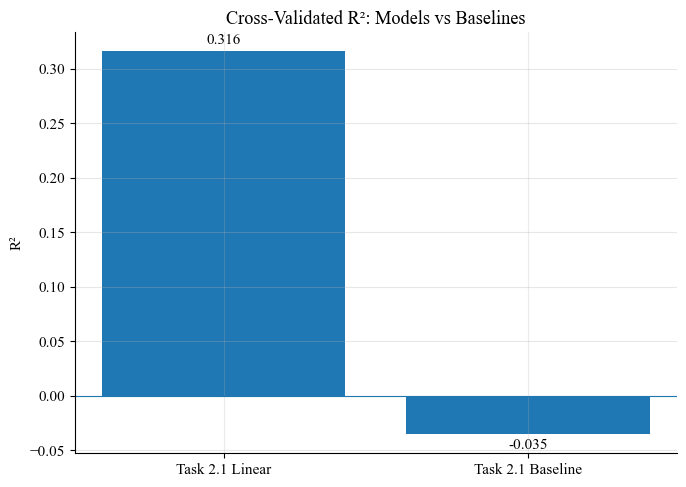

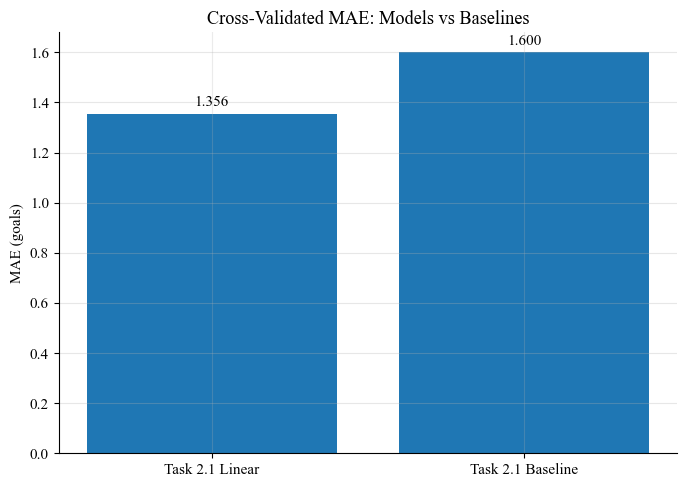

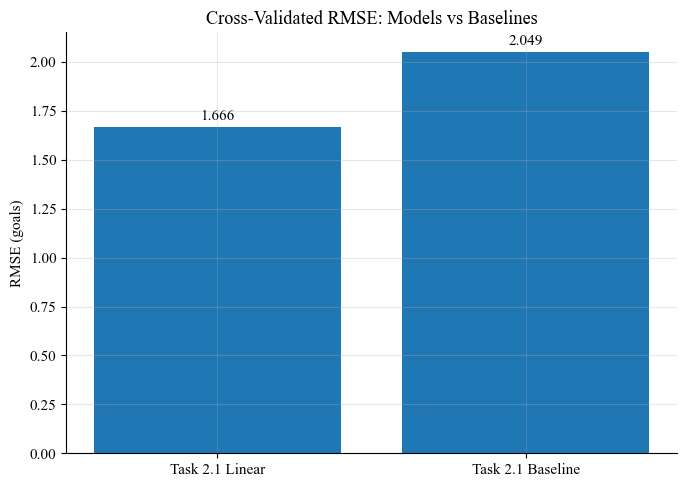

In [22]:
labels = ["Task 2.1 Linear", "Task 2.1 Baseline"]

def plot_metric(values, title, ylabel, zero_line=False):
    fig, ax = plt.subplots(figsize=(7, 5))
    bars = ax.bar(labels, values)
    if zero_line:
        ax.axhline(0, linewidth=0.8)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.bar_label(bars, fmt="%.3f", padding=3)
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    plt.show()

plot_metric([0.316, -0.035],
            "Cross-Validated R²: Models vs Baselines", "R²", True)
plot_metric([1.356, 1.600],
            "Cross-Validated MAE: Models vs Baselines", "MAE (goals)")
plot_metric([1.666, 2.049],
            "Cross-Validated RMSE: Models vs Baselines", "RMSE (goals)")


In [2]:
import matplotlib.pyplot as plt

# Chart 1: R-squared
plt.figure(figsize=(6, 4))
plt.bar(["R²"], [r2])
plt.ylim(min(0, r2 - 0.1), 1)
plt.title("Model Explained Variance (R²)")
plt.ylabel("R² score")
plt.text(0, r2, f"{r2:.3f}", ha="center", va="bottom")
plt.tight_layout()
plt.savefig("r_squared.png", dpi=300)
plt.show()


# Chart 2: Prediction errors
error_metrics = {
    "MAE": mae,
    "MSE": mse,
    "RMSE": rmse
}

plt.figure(figsize=(7, 4))
bars = plt.bar(error_metrics.keys(), error_metrics.values())
plt.title("Regression Prediction Errors")
plt.ylabel("Error value")
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, error_metrics.values()):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.3f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig("prediction_errors.png", dpi=300)
plt.show()

NameError: name 'r2' is not defined

<Figure size 600x400 with 0 Axes>